In [1]:
import os
import glob
import numpy as np
import pandas as pd
import nibabel as nib
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

c:\Users\juan_\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.25.905) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


In [2]:
# 1. Define custom PyTorch Dataset for Axial Slices
class COBRE_AxialDataset(Dataset):
    def __init__(self, subject_paths, labels, img_size=128):
        self.subject_paths = subject_paths
        self.labels = labels
        self.img_size = img_size
        
    def __len__(self):
        return len(self.subject_paths)
        
    def __getitem__(self, idx):
        img_path = self.subject_paths[idx]
        
        # Load 3D volume via nibabel
        nii_img = nib.load(img_path)
        volume = nii_img.get_fdata()
        
        # Extract central axial slice
        mid_slice_idx = volume.shape[2] // 2
        slice_2d = volume[:, :, mid_slice_idx]
        
        # Normalize intensity to [0, 1] range safely
        min_val, max_val = np.min(slice_2d), np.max(slice_2d)
        if max_val > min_val:
            slice_2d = (slice_2d - min_val) / (max_val - min_val)
        else:
            slice_2d = np.zeros_like(slice_2d)
            
        # Resize/pad to standard square dimensions (e.g., 128x128) using PyTorch interpolation
        tensor_slice = torch.tensor(slice_2d, dtype=torch.float32).unsqueeze(0).unsqueeze(0) # Shape: [1, 1, H, W]
        resized_slice = nn.functional.interpolate(tensor_slice, size=(self.img_size, self.img_size), mode='bilinear', align_corners=False)
        
        # Remove batch/channel extra dims to return [1, H, W]
        x = resized_slice.squeeze(0)
        y = torch.tensor(self.labels[idx], dtype=torch.long)
        
        return x, y

In [3]:
# 2. Prepare data mapping
data_dir = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset"
csv_path = os.path.join(data_dir, "participants.tsv")
df_participants = pd.read_csv(csv_path, sep='\t')

In [4]:
# Match available files with clinical labels
all_paths = sorted(glob.glob(os.path.join(data_dir, "sub-*", "anat", "*_T1w.nii.gz")))
path_dict = {os.path.basename(p).split('_')[0]: p for p in all_paths}

valid_participants = df_participants[df_participants['participant_id'].isin(path_dict.keys())].copy()
matched_paths = [path_dict[pid] for pid in valid_participants['participant_id']]

In [5]:
# Encode string labels (CONTROL, SCHZ, etc.) to integers
encoder = LabelEncoder()
encoded_labels = encoder.fit_transform(valid_participants['diagnosis'])
num_classes = len(encoder.classes_)

print(f"Classes detected: {list(encoder.classes_)}")
print(f"Total samples matched for Deep Learning: {len(matched_paths)}")

Classes detected: ['ADHD', 'BIPOLAR', 'CONTROL', 'SCHZ']
Total samples matched for Deep Learning: 265


In [6]:
# 3. Train/Val Split
X_train_p, X_val_p, y_train_l, y_val_l = train_test_split(
    matched_paths, encoded_labels, test_size=0.2, random_state=42, stratify=encoded_labels
)

train_dataset = COBRE_AxialDataset(X_train_p, y_train_l)
val_dataset = COBRE_AxialDataset(X_val_p, y_val_l)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

In [7]:
# 4. Define a robust 2D CNN Architecture
class SimpleBrainCNN(nn.Module):
    def __init__(self, num_classes):
        super(SimpleBrainCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 128 -> 64
            
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 64 -> 32
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 32 -> 16
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )
        
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = SimpleBrainCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

Using device: cpu


In [9]:
# 5. Quick Training Loop (e.g., 5 epochs to test baseline)
epochs = 5
print("\n--- Starting PyTorch CNN Training ---")
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}%")

print("\nTraining pipeline successfully executed!")


--- Starting PyTorch CNN Training ---
Epoch [1/5] | Loss: 3.8620 | Train Acc: 34.91%
Epoch [2/5] | Loss: 1.4688 | Train Acc: 33.96%
Epoch [3/5] | Loss: 1.3074 | Train Acc: 40.57%
Epoch [4/5] | Loss: 1.3173 | Train Acc: 35.85%
Epoch [5/5] | Loss: 1.2659 | Train Acc: 41.04%

Training pipeline successfully executed!


## Model metrics

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

In [11]:
# 1. Evaluate model on Validation Set
model.eval()
val_preds = []
val_targets = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        
        val_preds.extend(predicted.cpu().numpy())
        val_targets.extend(labels.numpy())

In [12]:
# 2. Compute Confusion Matrix
cm = confusion_matrix(val_targets, val_preds)
class_names = encoder.classes_

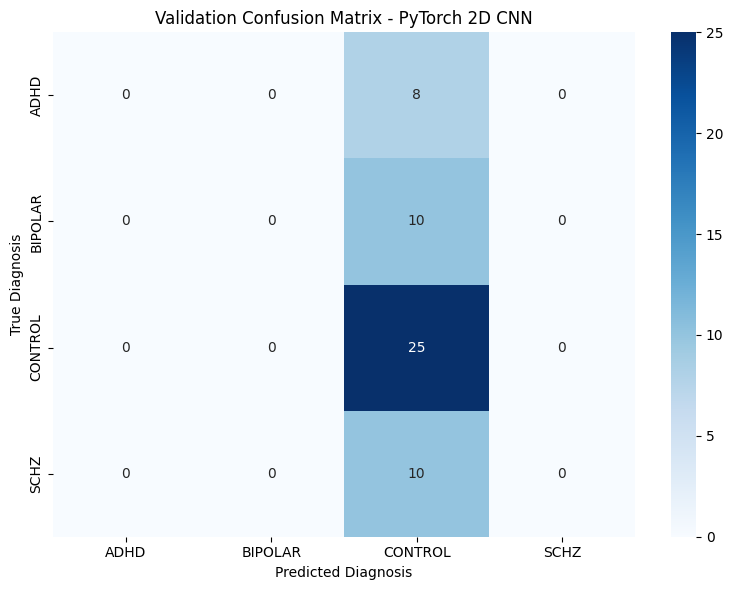

In [13]:
# 3. Plot Confusion Matrix and Performance Metrics
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Validation Confusion Matrix - PyTorch 2D CNN')
plt.xlabel('Predicted Diagnosis')
plt.ylabel('True Diagnosis')
plt.tight_layout()
plt.show()

In [14]:
# Print detailed metrics report
print("\n--- Classification Report (Validation Set) ---")
print(classification_report(val_targets, val_preds, target_names=class_names))


--- Classification Report (Validation Set) ---
              precision    recall  f1-score   support

        ADHD       0.00      0.00      0.00         8
     BIPOLAR       0.00      0.00      0.00        10
     CONTROL       0.47      1.00      0.64        25
        SCHZ       0.00      0.00      0.00        10

    accuracy                           0.47        53
   macro avg       0.12      0.25      0.16        53
weighted avg       0.22      0.47      0.30        53



c:\Users\juan_\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\juan_\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\juan_\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

## Performance per class

In [ ]:
# 1. Evaluate performance per class to isolate why the model collapsed to 'CONTROL' per class metrics
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = outputs.max(1)
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

In [16]:
# 2. Print strict classification report
class_names = encoder.classes_
print("--- Final Local Audit Report ---")
print(classification_report(all_targets, all_preds, target_names=class_names, zero_division=0))

# 3. Identify failure distribution
for idx, class_name in enumerate(class_names):
    class_mask = (all_targets == idx)
    if class_mask.sum() > 0:
        class_acc = (all_preds[class_mask] == idx).mean()
        print(f"Accuracy for class '{class_name}': {class_acc*100:.2f}% (Support: {class_mask.sum()})")

--- Final Local Audit Report ---
              precision    recall  f1-score   support

        ADHD       0.00      0.00      0.00         8
     BIPOLAR       0.00      0.00      0.00        10
     CONTROL       0.47      1.00      0.64        25
        SCHZ       0.00      0.00      0.00        10

    accuracy                           0.47        53
   macro avg       0.12      0.25      0.16        53
weighted avg       0.22      0.47      0.30        53

Accuracy for class 'ADHD': 0.00% (Support: 8)
Accuracy for class 'BIPOLAR': 0.00% (Support: 10)
Accuracy for class 'CONTROL': 100.00% (Support: 25)
Accuracy for class 'SCHZ': 0.00% (Support: 10)
